# Elastic Net: linear ML slice

**Question:** does a regularised linear model (Elastic Net) using all 10 features forecast next week's volatility better than HAR?

This notebook loads `data/processed/model_table.csv`, built by `Main_Notebook.ipynb`, and uses only the 2,452 training rows (30 Mar 2005 – 23 Dec 2014). The 717 test rows (2015–2017) are not used until the group's single test run on Wed 25 Nov, so the final test score stays an honest measure of performance on unseen data. The test-run cells are locked behind `RUN_TEST = False` until then.

Section 1 sets up the notebook and loads the data; section 2 explores features 4 and 6–8; section 3 checks the correlations between all 10 features.

## 1. Setup and data

Imports, moving to the repo root so file paths match the rest of the project, one figure style for all plots, and the lock for the test-run cells.

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Work from the repo root, like the main notebook (this notebook lives in slices/linear_ml/)
if os.path.basename(os.getcwd()) == "linear_ml":
    os.chdir("../..")

sns.set_theme(style="whitegrid", font_scale=1.1)
os.makedirs("results/figures", exist_ok=True)

RUN_TEST = False   # switch to True only on the test-run call, after the settings are frozen

### 1.1 Load the training rows

Every model loads the same table and the same training rows, so their scores can be compared fairly. Only the training rows are kept, and no test variable is created, so nothing in this notebook can see 2015–2017 before the test run. That is our guard against leakage.

In [7]:
# Read data
model_table = pd.read_csv("data/processed/model_table.csv", parse_dates=['date'])

train = model_table[model_table["split"] == "train"].reset_index(drop=True)

FEATURES = ["f1", "f2", "f3", "f4", "f5", "f6", "f7", "f8", "f9", "f10"]

print("Training rows:", len(train))
print("First date:", train["date"].min().date())
print("Last date:", train["date"].max().date())

Training rows: 2452
First date: 2005-03-30
Last date: 2014-12-23


## 2. Exploration of features 4, 6, 7 and 8

**Goal:** understand the four features one at a time before any model uses them.

The features are:
- f4: log VIX;
- f6: log volatility of the bond ETF (TLT) over 22 days;
- f7: log of bank ETF (XLF) volatility divided by SPY volatility, over 22 days;
- f8: the bond ETF's 22-day log return.

For each one we look at its typical value, spread, extremes and whether it has a long tail.

### 2.1 Summary Statistics

One table giving each feature's centre (mean, median), spread (standard deviation), extremes (min, max) and shape (skew).

The count proves that there are no missing values in the training rows.

In [8]:
# One row per feature: count, centre, spread, extremes and shape. Round to 3 decimals for display.
train[["f4", "f6", "f7", "f8"]].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T.round(3)

,count,mean,median,std,min,max,skew
f4,2452.0,2.917,2.848,0.399,2.292,4.393,0.925
f6,2452.0,-3.307,-3.344,0.380,-4.475,-2.232,0.270
f7,2452.0,0.360,0.311,0.250,-0.236,1.332,1.030
f8,2452.0,0.004,0.003,0.039,-0.153,0.245,0.732


### 2.2 Histograms

The table gives the numbers, while a histogram shows the shape. We look at where most days sit, and whether a few crisis days (such as 2008) form a long tail.

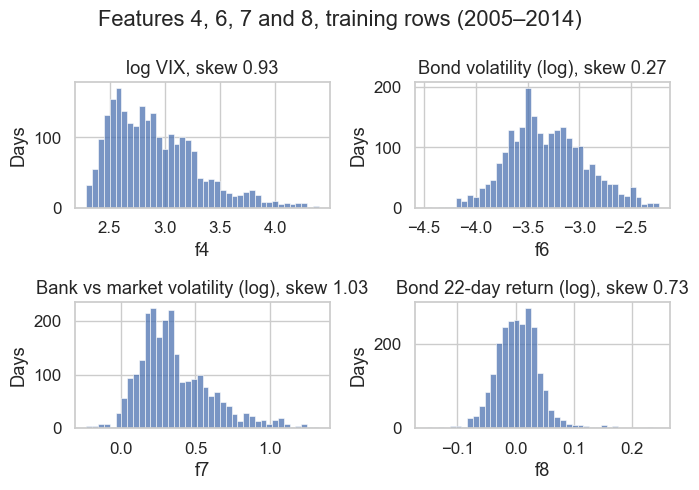

In [9]:
NAMES = {"f4": "log VIX",
         "f6": "Bond volatility (log)",
         "f7": "Bank vs market volatility (log)",
         "f8": "Bond 22-day return (log)"}

# Draw the histograms, one per feature
fig, axes = plt.subplots(2, 2, figsize=(7, 5))
for ax, col in zip(axes.flat, NAMES):
    sns.histplot(train[col], bins=40, ax=ax)
    ax.set_title(f"{NAMES[col]}, skew {train[col].skew():.2f}")
    ax.set_xlabel(col)
    ax.set_ylabel("Days")

fig.suptitle("Features 4, 6, 7 and 8, training rows (2005–2014)")

# Save histograms image under results folder
plt.tight_layout()
plt.savefig("results/figures/eda_hist_f4_f6_f7_f8.png", dpi=200)
plt.show()

## 2.3 Tails origin

Find where the tails are coming from.

In [10]:
# Where do the right tails come from? Years of each feature's 20 highest days (training rows)
for col in ["f4", "f7", "f8"]:
    top = train.nlargest(20, col)
    print(col, top["date"].dt.year.value_counts().sort_index().to_dict())

f4 {2008: 20}
f7 {2008: 18, 2009: 2}
f8 {2008: 17, 2011: 3}


### 2.4 Result

Our conclusions so far are below:
- All four features are complete on the 2,452 training rows (no missing values). 
- f6 (bond volatility) is roughly symmetric (skew 0.27). The other three have a right tail: 
    - f7 (bank vs market volatility, skew 1.03) reaches 1.332.
    - f4 (log VIX, skew 0.93) reaches 4.393.
    - f8 (bond 22-day return, skew 0.73) is symmetric around 0 apart from a few large positive returns up to 0.245.
- The largest values of f4, f7, and f8 come mostly from 2008, so the tails come from a small number of stressed periods. f4, f6 and f7 are already logs, and the remaining skew is moderate, so we apply no further transform.


# 3. Correlations between all 10 features

This section aims to check whether some features carry the same information. That is the evidence for choosing Elastic Net over plain regression: if two features move together, plain regression can't tell which one deserves the credit and give unstable coefficients. Meanwhile, Elastic Net shares the credit between them. Having high correlations in a heatmap show the problem that Elastic Net solves.

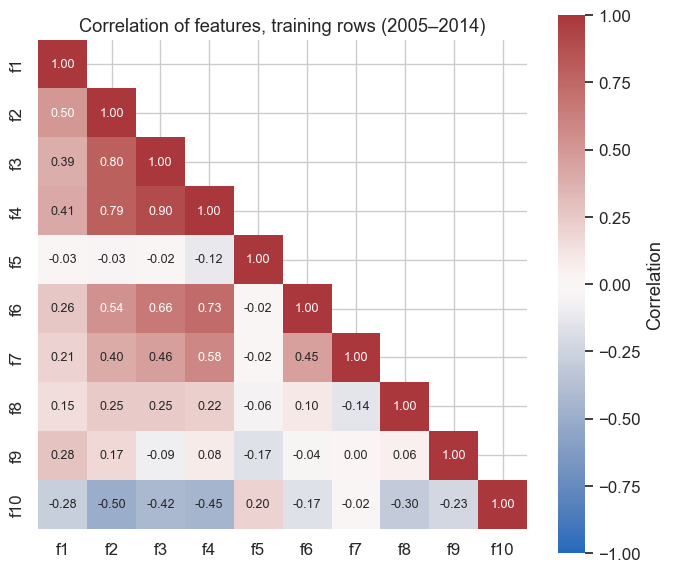

f3 vs f4 (log 22-day volatility vs log VIX): 0.897
f4  f3    0.897
f3  f2    0.797
f4  f2    0.790
f6  f4    0.727
dtype: float64


In [ ]:
# Correlation of every pair of features of the training rows only.
corr = train[FEATURES].corr()

# Hide the upper half of the correlation matrix, since it is symmetric and the diagonal is always 1.0.
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag",
            vmin=-1, vmax=1, center=0, square=True,
            annot_kws={"size": 9}, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlation of features, training rows (2005–2014)")
plt.tight_layout()
plt.savefig("results/figures/eda_corr_heatmap.png", dpi=200)
plt.show()

# f3 and f4 both describe SPY's volatility, so it is expected for them to move together.
print(f"f3 vs f4 (log 22-day volatility vs log VIX): {corr.loc['f3', 'f4']:.3f}")

# Every other strongly correlated pair (|r| >= 0.7), strongest first
pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack()
print(pairs[pairs.abs() >= 0.7].sort_values(key=abs, ascending=False).round(3))
